# Phát hiện Deepfake qua ẢNH — Machine Learning (đặc trưng thủ công)

Notebook 1/…: chỉ làm **ML trên ảnh** (dataset `data-raw/data/Dataset`). Các phần còn lại (DL ảnh, video) làm ở notebook riêng sau.

**Quy trình:**

0. Cài đặt & tìm dữ liệu
1. Lấy ảnh + tiền xử lý (cắt mặt, lọc mờ/trùng, chia train/test, cân bằng lớp bằng augmentation)
2. Trích xuất đặc trưng thủ công: **LBP, HOG, FFT, Color Histogram** (2311 đặc trưng/ảnh)
   - 2.1 Bảng đặc trưng dễ đọc (tên cột tiếng Việt, so sánh Thật vs Giả)
3. Phân tích khám phá dữ liệu (EDA)
4. Huấn luyện & so sánh **7 thuật toán ML**: Logistic Regression, KNN, Naive Bayes, Decision Tree, Random Forest, SVM, Gradient Boosting
5. Lưu model tốt nhất `outputs/best_model.pkl` (dùng lại cho phần video sau này)

**Dữ liệu:** `data/Dataset/{Train,Validation,Test}/{Real,Fake}` — mỗi lần chạy lấy ngẫu nhiên `N_PER_CLASS` ảnh mỗi lớp (đặt ở cell lấy ảnh), rồi Bước 1 chia lại train/test.

In [1]:
import os, glob

# Cấu trúc data-raw: .../data/Dataset/{Train,Validation,Test}/{Real,Fake}
CANDIDATES = [
    "/kaggle/input/datasets/whissnguyen/data-raw/data",
    "/kaggle/input/data-raw/data",
]
DATA_DIR = next((c for c in CANDIDATES if os.path.isdir(os.path.join(c, "Dataset"))), None)

if DATA_DIR is None:   # không đoán đúng -> tự dò (giới hạn độ sâu để khỏi quét hàng chục nghìn ảnh)
    for root, dirs, _ in os.walk("/kaggle/input"):
        if root.count("/") - 2 > 5:
            dirs.clear()
            continue
        if "Dataset" in dirs:
            DATA_DIR = root
            break
if DATA_DIR is None:
    raise FileNotFoundError("Không thấy thư mục Dataset - kiểm tra lại Add Data 'data-raw'.")

DATASET_DIR = os.path.join(DATA_DIR, "Dataset")
print("DATASET_DIR:", DATASET_DIR)
for sp in ("Train", "Validation", "Test"):
    for lb in ("Real", "Fake"):
        d = os.path.join(DATASET_DIR, sp, lb)
        print(f"  {sp}/{lb}:", len(os.listdir(d)) if os.path.isdir(d) else "KHÔNG CÓ")

DATASET_DIR: /kaggle/input/datasets/trnganv/data-raw/data/Dataset
  Train/Real: 70001
  Train/Fake: 70001
  Validation/Real: 19787
  Validation/Fake: 19641
  Test/Real: 5413
  Test/Fake: 5492


## 0. Cài đặt thư viện & cấu hình đường dẫn

Chạy cell bên dưới 1 lần để cài các thư viện cần thiết (bỏ qua nếu môi
trường đã có sẵn).

In [2]:
# Bỏ dấu # ở dòng dưới nếu môi trường chưa cài các thư viện cần thiết
#!pip install opencv-python numpy pandas scikit-learn scikit-image matplotlib joblib tqdm Pillow

In [3]:
!pip install -U scikit-learn #Phiên bản scikit-learn mới nhất

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 82.0 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1


In [4]:
import os
import glob
import shutil
import random
import warnings
from dataclasses import dataclass, field

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from tqdm.notebook import tqdm

warnings.filterwarnings("ignore")
%matplotlib inline


In [5]:
import os, glob, shutil, random

N_PER_CLASS = 10000                                  # số ảnh mỗi lớp (tăng/giảm tùy RAM, thời gian)
SPLITS = ("Train", "Validation", "Test")            # gộp cả 3 tập, Bước 1 sẽ tự chia train/test lại
VALID = (".jpg", ".jpeg", ".png")
random.seed(42)

destination = "/kaggle/working/data/raw"
shutil.rmtree(destination, ignore_errors=True)

for label in ("Real", "Fake"):
    files = []
    for sp in SPLITS:
        folder = os.path.join(DATASET_DIR, sp, label)
        if os.path.isdir(folder):
            files += [os.path.join(folder, f) for f in os.listdir(folder) if f.lower().endswith(VALID)]
    random.shuffle(files)
    files = files[:N_PER_CLASS]

    out = os.path.join(destination, label)
    os.makedirs(out, exist_ok=True)
    for i, p in enumerate(files):
        shutil.copy2(p, os.path.join(out, f"{label.lower()}_{i:06d}{os.path.splitext(p)[1].lower()}"))
    print(f"{label}: đã copy {len(files)} ảnh -> {out}")

print("Files:", os.listdir(destination))


Real: đã copy 10000 ảnh -> /kaggle/working/data/raw/Real
Fake: đã copy 10000 ảnh -> /kaggle/working/data/raw/Fake
Files: ['Real', 'Fake']


In [6]:
# ===================== CẤU HÌNH ĐƯỜNG DẪN & THAM SỐ =====================
# Chỉnh lại các đường dẫn/tham số này cho phù hợp với môi trường của bạn.

RAW_DIR = "data/raw"                 # ảnh thô: RAW_DIR/{Real,Fake}
PROCESSED_DIR = "data/processed"     # sau bước 1 sẽ có PROCESSED_DIR/{train,test}/{Real,Fake}
OUTPUT_DIR = "outputs"
EDA_DIR = os.path.join(OUTPUT_DIR, "eda")
FEATURES_CSV = os.path.join(OUTPUT_DIR, "features.csv")

IMG_SIZE = 128  # phải khớp giữa bước tiền xử lý và bước trích đặc trưng

for d in (PROCESSED_DIR, OUTPUT_DIR, EDA_DIR):
    os.makedirs(d, exist_ok=True)

print("RAW_DIR       :", os.path.abspath(RAW_DIR))
print("PROCESSED_DIR :", os.path.abspath(PROCESSED_DIR))
print("OUTPUT_DIR    :", os.path.abspath(OUTPUT_DIR))


RAW_DIR       : /kaggle/working/data/raw
PROCESSED_DIR : /kaggle/working/data/processed
OUTPUT_DIR    : /kaggle/working/outputs


## 1. Tiền xử lý ảnh thô (tương đương `src/preprocess_data.py`)

Bước này đọc ảnh từ `data/raw/{Real,Fake}` (frame trích từ video, hoặc ảnh
còn dính nền/nhiều người) và thực hiện lần lượt:

1. **Face detection + crop** — chỉ giữ vùng khuôn mặt (bỏ nền/nhiễu)
2. **Lọc ảnh mờ** — dựa trên phương sai Laplacian
3. **Lọc ảnh trùng lặp** — average hash (aHash) + Hamming distance
4. **Chia train/test theo ảnh gốc đã lọc sạch** — làm **trước** augmentation
5. **Cân bằng lớp (class balancing)** — augmentation (xoay nhẹ, lật, đổi độ
   sáng) chỉ áp dụng cho tập **train** của lớp thiểu số

> **Vì sao chia train/test trước rồi mới augment?** Nếu augment trước, ảnh
> gốc và bản augment của nó (gần như giống hệt) có thể rơi vào cả train
> lẫn test → model "nhìn thấy" ảnh gần giống test ngay lúc train → điểm số
> bị thổi phồng ảo (data leakage). Thứ tự trong notebook này (split trước,
> augment sau, augment chỉ trong train) tránh được rủi ro đó.

Kết quả được ghi ra `data/processed/train/{Real,Fake}` và
`data/processed/test/{Real,Fake}`.

> **Bỏ qua bước này nếu** ảnh của bạn đã được crop mặt sẵn và đã nằm trong
> `data/processed/{Real,Fake}` (không cần cấu trúc train/test) — nhảy thẳng
> tới **Bước 2**.

In [7]:
VALID_EXTS = (".jpg", ".jpeg", ".png")
CLASSES = ("Real", "Fake")

# --------------------------------------------------------------------- #
# 1) FACE DETECTION + CROP
# --------------------------------------------------------------------- #
_FACE_CASCADE = None


def get_face_detector() -> cv2.CascadeClassifier:
    """Load Haar Cascade face detector 1 lần duy nhất (cache)."""
    global _FACE_CASCADE
    if _FACE_CASCADE is None:
        cascade_path = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
        _FACE_CASCADE = cv2.CascadeClassifier(cascade_path)
    return _FACE_CASCADE


def detect_and_crop_face(bgr_img: np.ndarray, margin: float = 0.3):
    """
    Phát hiện khuôn mặt lớn nhất trong ảnh và crop kèm margin xung quanh.
    Trả về (cropped_img, found_face: bool). Nếu không tìm thấy mặt, trả về
    ảnh gốc (giả định đã crop sẵn) kèm found_face=False.
    """
    detector = get_face_detector()
    gray = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2GRAY)
    faces = detector.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40)
    )

    if len(faces) == 0:
        return bgr_img, False

    x, y, w, h = max(faces, key=lambda f: f[2] * f[3])

    mx, my = int(w * margin), int(h * margin)
    h_img, w_img = bgr_img.shape[:2]
    x0 = max(0, x - mx)
    y0 = max(0, y - my)
    x1 = min(w_img, x + w + mx)
    y1 = min(h_img, y + h + my)

    cropped = bgr_img[y0:y1, x0:x1]
    if cropped.size == 0:
        return bgr_img, False
    return cropped, True


In [8]:
# --------------------------------------------------------------------- #
# 2) BLUR / QUALITY FILTER
# --------------------------------------------------------------------- #

def is_blurry(bgr_img: np.ndarray, threshold: float = 80.0) -> bool:
    """
    Ảnh càng nét thì phương sai Laplacian càng cao. threshold nên tinh
    chỉnh theo dataset thực tế (in thử phân phối giá trị nếu cần).
    """
    gray = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2GRAY)
    variance = cv2.Laplacian(gray, cv2.CV_64F).var()
    return variance < threshold


# --------------------------------------------------------------------- #
# 3) DUPLICATE DETECTION (average hash)
# --------------------------------------------------------------------- #

def average_hash(bgr_img: np.ndarray, hash_size: int = 8) -> np.ndarray:
    """aHash: resize về (hash_size x hash_size), so mỗi pixel với giá trị
    trung bình -> chuỗi bit. Ảnh gần giống nhau sẽ có hash gần giống nhau."""
    gray = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2GRAY)
    small = cv2.resize(gray, (hash_size, hash_size), interpolation=cv2.INTER_AREA)
    avg = small.mean()
    return (small > avg).flatten()


def hamming_distance(hash_a: np.ndarray, hash_b: np.ndarray) -> int:
    return int(np.count_nonzero(hash_a != hash_b))


class DuplicateFilter:
    """Theo dõi hash đã thấy trong từng lớp (Real/Fake riêng biệt) ở giai
    đoạn làm sạch, trước khi chia train/test."""

    def __init__(self, max_distance: int = 5):
        self.max_distance = max_distance
        self.seen: dict = {}

    def is_duplicate(self, label: str, img_hash: np.ndarray) -> bool:
        for existing in self.seen.get(label, []):
            if hamming_distance(existing, img_hash) <= self.max_distance:
                return True
        return False

    def add(self, label: str, img_hash: np.ndarray):
        self.seen.setdefault(label, []).append(img_hash)


In [9]:
# --------------------------------------------------------------------- #
# 4) DATA AUGMENTATION (chỉ dùng cho tập TRAIN, để cân bằng lớp)
# --------------------------------------------------------------------- #

def augment_rotate(img: np.ndarray, max_angle: float = 10.0) -> np.ndarray:
    angle = random.uniform(-max_angle, max_angle)
    h, w = img.shape[:2]
    matrix = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    return cv2.warpAffine(img, matrix, (w, h), borderMode=cv2.BORDER_REFLECT)


def augment_flip(img: np.ndarray) -> np.ndarray:
    return cv2.flip(img, 1)


def augment_brightness(img: np.ndarray, delta_range: int = 30) -> np.ndarray:
    delta = random.randint(-delta_range, delta_range)
    return cv2.convertScaleAbs(img, alpha=1.0, beta=delta)


def random_augment(img: np.ndarray) -> np.ndarray:
    """Áp ngẫu nhiên 1-2 phép biến đổi để tạo ảnh mới đa dạng hơn."""
    ops = [augment_rotate, augment_flip, augment_brightness]
    chosen = random.sample(ops, k=random.choice([1, 2]))
    out = img.copy()
    for op in chosen:
        out = op(out)
    return out


# --------------------------------------------------------------------- #
# STATS
# --------------------------------------------------------------------- #

@dataclass
class Stats:
    scanned: int = 0
    no_face: int = 0
    dropped_blurry: int = 0
    dropped_duplicate: int = 0
    dropped_unreadable: int = 0
    cleaned: dict = field(default_factory=lambda: {"Real": 0, "Fake": 0})
    train_kept: dict = field(default_factory=lambda: {"Real": 0, "Fake": 0})
    test_kept: dict = field(default_factory=lambda: {"Real": 0, "Fake": 0})
    train_augmented: dict = field(default_factory=lambda: {"Real": 0, "Fake": 0})


In [10]:
# --------------------------------------------------------------------- #
# STAGE A — làm sạch (chưa chia train/test): face crop, blur filter, dedup
# --------------------------------------------------------------------- #

def _clean_raw_images(raw_dir, scratch_dir, stats, blur_threshold, dup_max_distance, face_margin):
    """Trả về dict label -> list đường dẫn ảnh đã làm sạch (trong scratch_dir)."""
    dup_filter = DuplicateFilter(max_distance=dup_max_distance)
    cleaned_paths = {label: [] for label in CLASSES}

    for label in CLASSES:
        src_folder = os.path.join(raw_dir, label)
        scratch_label_dir = os.path.join(scratch_dir, label)
        os.makedirs(scratch_label_dir, exist_ok=True)

        img_paths = [
            p for p in glob.glob(os.path.join(src_folder, "*"))
            if p.lower().endswith(VALID_EXTS)
        ]
        print(f"[INFO] {label}: tìm thấy {len(img_paths)} ảnh thô trong {src_folder}")

        for idx, p in enumerate(tqdm(img_paths, desc=f"Làm sạch {label}")):
            stats.scanned += 1
            img = cv2.imread(p)
            if img is None:
                stats.dropped_unreadable += 1
                continue

            cropped, found = detect_and_crop_face(img, margin=face_margin)
            if not found:
                stats.no_face += 1

            resized = cv2.resize(cropped, (IMG_SIZE, IMG_SIZE))

            if is_blurry(resized, threshold=blur_threshold):
                stats.dropped_blurry += 1
                continue

            img_hash = average_hash(resized)
            if dup_filter.is_duplicate(label, img_hash):
                stats.dropped_duplicate += 1
                continue
            dup_filter.add(label, img_hash)

            out_path = os.path.join(scratch_label_dir, f"{label.lower()}_{idx:06d}.jpg")
            cv2.imwrite(out_path, resized)
            cleaned_paths[label].append(out_path)
            stats.cleaned[label] += 1

    return cleaned_paths


# --------------------------------------------------------------------- #
# STAGE B — chia train/test theo ảnh gốc ĐÃ LÀM SẠCH (chưa augment)
# --------------------------------------------------------------------- #

def _split_and_move(cleaned_paths, processed_dir, test_size, seed, stats):
    rng = random.Random(seed)
    final_paths = {"train": {}, "test": {}}

    for label in CLASSES:
        paths = list(cleaned_paths[label])
        rng.shuffle(paths)
        n_test = int(round(len(paths) * test_size))
        test_subset = paths[:n_test]
        train_subset = paths[n_test:]

        for split_name, subset in (("train", train_subset), ("test", test_subset)):
            dst_dir = os.path.join(processed_dir, split_name, label)
            os.makedirs(dst_dir, exist_ok=True)
            moved = []
            for i, src in enumerate(subset):
                dst = os.path.join(dst_dir, f"{label.lower()}_{i:06d}.jpg")
                shutil.move(src, dst)
                moved.append(dst)
            final_paths[split_name][label] = moved

        stats.train_kept[label] = len(train_subset)
        stats.test_kept[label] = len(test_subset)

    return final_paths


# --------------------------------------------------------------------- #
# STAGE C — cân bằng lớp bằng augmentation, CHỈ trong tập train
# --------------------------------------------------------------------- #

def _balance_train_classes(train_paths, processed_dir, stats, max_aug_multiplier):
    n_real = len(train_paths["Real"])
    n_fake = len(train_paths["Fake"])
    if n_real == 0 or n_fake == 0:
        print("[WARN] Một trong hai lớp không có ảnh train nào sau lọc -> bỏ qua cân bằng lớp.")
        return

    majority_label, minority_label = ("Real", "Fake") if n_real >= n_fake else ("Fake", "Real")
    n_majority = max(n_real, n_fake)
    n_minority = min(n_real, n_fake)
    target = min(n_majority, int(n_minority * max_aug_multiplier))
    n_to_generate = max(0, target - n_minority)

    if n_to_generate == 0:
        print(f"[INFO] Tập train đã tương đối cân bằng (Real={n_real}, Fake={n_fake}), bỏ qua augmentation.")
        return

    print(
        f"[INFO] Tập TRAIN mất cân bằng: {majority_label}={n_majority}, {minority_label}={n_minority}. "
        f"Sinh thêm {n_to_generate} ảnh augment cho lớp '{minority_label}' (chỉ trong train, "
        f"giới hạn tối đa {max_aug_multiplier}x số ảnh gốc để tránh trùng lặp quá nhiều)."
    )

    minority_paths = train_paths[minority_label]
    dst_folder = os.path.join(processed_dir, "train", minority_label)

    for i in tqdm(range(n_to_generate), desc=f"Augment train/{minority_label}"):
        src_path = random.choice(minority_paths)
        img = cv2.imread(src_path)
        if img is None:
            continue
        aug_img = random_augment(img)
        out_name = f"{minority_label.lower()}_aug_{i:06d}.jpg"
        out_path = os.path.join(dst_folder, out_name)
        cv2.imwrite(out_path, aug_img)
        stats.train_augmented[minority_label] += 1


In [11]:
# --------------------------------------------------------------------- #
# MAIN PIPELINE (tiền xử lý)
# --------------------------------------------------------------------- #

def process_dataset(
    raw_dir, processed_dir,
    blur_threshold=80.0, dup_max_distance=5, face_margin=0.3,
    balance=True, max_aug_multiplier=3.0, test_size=0.2, seed=42,
) -> Stats:
    stats = Stats()
    scratch_dir = os.path.join(processed_dir, "_scratch_clean")

    cleaned_paths = _clean_raw_images(
        raw_dir, scratch_dir, stats, blur_threshold, dup_max_distance, face_margin
    )
    final_paths = _split_and_move(cleaned_paths, processed_dir, test_size, seed, stats)
    shutil.rmtree(scratch_dir, ignore_errors=True)

    if balance:
        _balance_train_classes(final_paths["train"], processed_dir, stats, max_aug_multiplier)

    _print_report(stats, test_size)
    return stats


def _print_report(stats: Stats, test_size: float):
    print("\n===== BÁO CÁO TIỀN XỬ LÝ DỮ LIỆU =====")
    print(f"Tổng số ảnh thô đã quét      : {stats.scanned}")
    print(f"Không đọc được (lỗi file)     : {stats.dropped_unreadable}")
    print(f"Không phát hiện được mặt      : {stats.no_face} (vẫn giữ, dùng ảnh gốc)")
    print(f"Loại vì quá mờ                : {stats.dropped_blurry}")
    print(f"Loại vì trùng lặp             : {stats.dropped_duplicate}")
    print(f"Sạch sau lọc (trước khi chia) -> Real: {stats.cleaned['Real']:5d} | Fake: {stats.cleaned['Fake']:5d}")
    print(f"\nChia train/test (test_size={test_size}, split theo ẢNH GỐC trước augment):")
    print(f"  TRAIN (trước augment) -> Real: {stats.train_kept['Real']:5d} | Fake: {stats.train_kept['Fake']:5d}")
    print(f"  TEST  (giữ nguyên, KHÔNG augment) -> Real: {stats.test_kept['Real']:5d} | Fake: {stats.test_kept['Fake']:5d}")
    print(f"  Augment thêm vào TRAIN -> Real: {stats.train_augmented['Real']:5d} | Fake: {stats.train_augmented['Fake']:5d}")
    train_real_final = stats.train_kept["Real"] + stats.train_augmented["Real"]
    train_fake_final = stats.train_kept["Fake"] + stats.train_augmented["Fake"]
    print(f"  TRAIN TỔNG cuối cùng -> Real: {train_real_final:5d} | Fake: {train_fake_final:5d}")
    print(
        "\n(Test set không augment và không cân bằng lớp — giữ đúng phân bố tự nhiên "
        "để đánh giá model khách quan, tránh data leakage giữa train/test.)"
    )


### Chạy tiền xử lý

Chỉnh các tham số bên dưới nếu cần rồi chạy cell (bỏ qua cell này nếu dữ
liệu của bạn đã nằm sẵn trong `data/processed/{Real,Fake}` dạng đã crop
mặt).

In [12]:
RUN_PREPROCESS = True  # đặt False nếu ảnh đã crop mặt sẵn trong data/processed/{Real,Fake}

if RUN_PREPROCESS:
    stats = process_dataset(
        raw_dir=RAW_DIR,
        processed_dir=PROCESSED_DIR,
        blur_threshold=80.0,
        dup_max_distance=5,
        face_margin=0.3,
        balance=True,
        max_aug_multiplier=3.0,
        test_size=0.2,
        seed=42,
    )
else:
    print("[SKIP] Bỏ qua bước tiền xử lý ảnh thô.")


[INFO] Real: tìm thấy 10000 ảnh thô trong data/raw/Real


Làm sạch Real:   0%|          | 0/10000 [00:00<?, ?it/s]

[INFO] Fake: tìm thấy 10000 ảnh thô trong data/raw/Fake


Làm sạch Fake:   0%|          | 0/10000 [00:00<?, ?it/s]

[INFO] Tập TRAIN mất cân bằng: Fake=6280, Real=5805. Sinh thêm 475 ảnh augment cho lớp 'Real' (chỉ trong train, giới hạn tối đa 3.0x số ảnh gốc để tránh trùng lặp quá nhiều).


Augment train/Real:   0%|          | 0/475 [00:00<?, ?it/s]


===== BÁO CÁO TIỀN XỬ LÝ DỮ LIỆU =====
Tổng số ảnh thô đã quét      : 20000
Không đọc được (lỗi file)     : 0
Không phát hiện được mặt      : 3048 (vẫn giữ, dùng ảnh gốc)
Loại vì quá mờ                : 2315
Loại vì trùng lặp             : 2579
Sạch sau lọc (trước khi chia) -> Real:  7256 | Fake:  7850

Chia train/test (test_size=0.2, split theo ẢNH GỐC trước augment):
  TRAIN (trước augment) -> Real:  5805 | Fake:  6280
  TEST  (giữ nguyên, KHÔNG augment) -> Real:  1451 | Fake:  1570
  Augment thêm vào TRAIN -> Real:   475 | Fake:     0
  TRAIN TỔNG cuối cùng -> Real:  6280 | Fake:  6280

(Test set không augment và không cân bằng lớp — giữ đúng phân bố tự nhiên để đánh giá model khách quan, tránh data leakage giữa train/test.)


## 2. Trích xuất đặc trưng (tương đương `src/feature_extraction.py`)

Trích xuất đặc trưng thủ công (hand-crafted features) từ ảnh khuôn mặt:

1. **LBP** (Local Binary Pattern) — bắt texture bất thường trên da / vùng blend
2. **HOG** (Histogram of Oriented Gradients) — bắt cấu trúc cạnh khuôn mặt
3. **FFT** (Fast Fourier Transform) — bắt artifact ở miền tần số cao (dấu vết GAN)
4. **Color Histogram** (HSV) — bắt lệch màu da do ghép mặt

Quét thư mục `data/processed/{Real,Fake}` (hoặc `data/processed/{train,test}/{Real,Fake}`
nếu đã chạy Bước 1) và xuất ra `outputs/features.csv`.

In [13]:
from skimage.feature import local_binary_pattern, hog

LBP_RADIUS = 2
LBP_POINTS = 8 * LBP_RADIUS


def extract_lbp(gray_img: np.ndarray) -> np.ndarray:
    """Trả về histogram LBP đã chuẩn hóa (uniform pattern)."""
    lbp = local_binary_pattern(gray_img, LBP_POINTS, LBP_RADIUS, method="uniform")
    n_bins = LBP_POINTS + 2
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins))
    hist = hist.astype("float32")
    hist /= (hist.sum() + 1e-7)
    return hist


def extract_hog(gray_img: np.ndarray) -> np.ndarray:
    """Trả về vector đặc trưng HOG."""
    features = hog(
        gray_img, orientations=9, pixels_per_cell=(16, 16),
        cells_per_block=(2, 2), block_norm="L2-Hys", feature_vector=True,
    )
    return features.astype("float32")


def extract_fft_features(gray_img: np.ndarray) -> np.ndarray:
    """
    Trích đặc trưng miền tần số bằng FFT 2D. Deepfake (đặc biệt ảnh GAN)
    thường để lại năng lượng bất thường ở dải tần số cao. Chia phổ tần số
    thành các dải vòng (radial bins) và lấy năng lượng trung bình mỗi dải.
    """
    f = np.fft.fft2(gray_img)
    fshift = np.fft.fftshift(f)
    magnitude = np.log1p(np.abs(fshift))

    h, w = magnitude.shape
    cy, cx = h // 2, w // 2
    y, x = np.indices((h, w))
    r = np.sqrt((x - cx) ** 2 + (y - cy) ** 2).astype(int)

    n_bins = 16
    max_r = r.max()
    bin_edges = np.linspace(0, max_r, n_bins + 1)
    radial_features = []
    for i in range(n_bins):
        mask = (r >= bin_edges[i]) & (r < bin_edges[i + 1])
        if mask.sum() > 0:
            radial_features.append(magnitude[mask].mean())
        else:
            radial_features.append(0.0)

    radial_features = np.array(radial_features, dtype="float32")
    low = radial_features[: n_bins // 3].sum() + 1e-7
    high = radial_features[2 * n_bins // 3 :].sum()
    ratio = np.array([high / low], dtype="float32")

    return np.concatenate([radial_features, ratio])


def extract_color_histogram(bgr_img: np.ndarray) -> np.ndarray:
    """Histogram màu trong không gian HSV (bắt lệch tông da khi ghép mặt)."""
    hsv = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist([hsv], [0, 1, 2], None, [8, 8, 8], [0, 180, 0, 256, 0, 256])
    hist = cv2.normalize(hist, hist).flatten()
    return hist.astype("float32")


def extract_features(bgr_img: np.ndarray) -> np.ndarray:
    """Ghép toàn bộ đặc trưng thành 1 vector duy nhất cho 1 ảnh."""
    bgr_img = cv2.resize(bgr_img, (IMG_SIZE, IMG_SIZE))
    gray = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2GRAY)

    lbp_feat = extract_lbp(gray)
    hog_feat = extract_hog(gray)
    fft_feat = extract_fft_features(gray)
    color_feat = extract_color_histogram(bgr_img)

    return np.concatenate([lbp_feat, hog_feat, fft_feat, color_feat])


In [14]:
def build_dataset(data_dir: str, output_csv: str) -> pd.DataFrame:
    """
    Trích đặc trưng cho toàn bộ ảnh và lưu ra 1 file CSV: cột 'label'
    (0=Fake, 1=Real) + các cột đặc trưng.

    Tự nhận diện 2 kiểu cấu trúc thư mục:
      a) data_dir/{train,test}/{Real,Fake} (do Bước 1 tạo ra)
         -> thêm cột "split" (train/test) vào CSV
      b) data_dir/{Real,Fake} (không có train/test)
         -> không có cột "split", Bước 4 sẽ tự chia ngẫu nhiên
    """
    train_dir = os.path.join(data_dir, "train")
    test_dir = os.path.join(data_dir, "test")
    use_split_mode = os.path.isdir(train_dir) and os.path.isdir(test_dir)

    if use_split_mode:
        scan_targets = [("train", train_dir), ("test", test_dir)]
        print("[INFO] Phát hiện cấu trúc train/test -> sẽ gắn cột 'split' vào features.csv.")
    else:
        scan_targets = [(None, data_dir)]

    rows, labels, splits = [], [], []

    for split_name, base_dir in scan_targets:
        for label_name, label_val in [("Real", 1), ("Fake", 0)]:
            folder = os.path.join(base_dir, label_name)
            img_paths = (
                glob.glob(os.path.join(folder, "*.jpg"))
                + glob.glob(os.path.join(folder, "*.jpeg"))
                + glob.glob(os.path.join(folder, "*.png"))
            )
            tag = f"{split_name}/{label_name}" if split_name else label_name
            print(f"[INFO] {tag}: tìm thấy {len(img_paths)} ảnh")

            for p in tqdm(img_paths, desc=f"Trích đặc trưng {tag}"):
                img = cv2.imread(p)
                if img is None:
                    continue
                feat = extract_features(img)
                rows.append(feat)
                labels.append(label_val)
                if use_split_mode:
                    splits.append(split_name)

    if len(rows) == 0:
        raise RuntimeError(
            f"Không tìm thấy ảnh nào trong {data_dir}. Kiểm tra lại cấu trúc thư mục "
            "(data/processed/Real, data/processed/Fake hoặc "
            "data/processed/train|test/Real, .../Fake nếu đã chạy Bước 1)."
        )

    X = np.vstack(rows)
    col_names = [f"f_{i}" for i in range(X.shape[1])]
    df = pd.DataFrame(X, columns=col_names)
    df["label"] = labels
    if use_split_mode:
        df["split"] = splits

    os.makedirs(os.path.dirname(output_csv), exist_ok=True)
    df.to_csv(output_csv, index=False)
    print(f"[OK] Đã lưu {len(df)} mẫu, {X.shape[1]} đặc trưng -> {output_csv}")
    return df


### Chạy trích xuất đặc trưng

In [15]:
features_df = build_dataset(PROCESSED_DIR, FEATURES_CSV)
features_df.head()


[INFO] Phát hiện cấu trúc train/test -> sẽ gắn cột 'split' vào features.csv.
[INFO] train/Real: tìm thấy 6280 ảnh


Trích đặc trưng train/Real:   0%|          | 0/6280 [00:00<?, ?it/s]

[INFO] train/Fake: tìm thấy 6280 ảnh


Trích đặc trưng train/Fake:   0%|          | 0/6280 [00:00<?, ?it/s]

[INFO] test/Real: tìm thấy 1451 ảnh


Trích đặc trưng test/Real:   0%|          | 0/1451 [00:00<?, ?it/s]

[INFO] test/Fake: tìm thấy 1570 ảnh


Trích đặc trưng test/Fake:   0%|          | 0/1570 [00:00<?, ?it/s]

[OK] Đã lưu 15581 mẫu, 2311 đặc trưng -> outputs/features.csv


,f_0,f_1,f_2,f_3,f_4,f_5,f_6,f_7,f_8,f_9,...,f_2303,f_2304,f_2305,f_2306,f_2307,f_2308,f_2309,f_2310,label,split
0,0.047058,0.029663,0.026917,0.024109,0.022156,0.030945,0.041992,0.072021,0.105835,0.079468,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,1,train
1,0.029114,0.023926,0.024048,0.025757,0.028015,0.039062,0.059814,0.108643,0.185486,0.109497,...,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,1,train
2,0.028687,0.025085,0.031250,0.029968,0.026367,0.032654,0.045044,0.101929,0.205994,0.115601,...,0.001318,0.000330,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,1,train
3,0.033508,0.024597,0.025940,0.023376,0.024719,0.037170,0.053101,0.099670,0.152161,0.106262,...,0.062325,0.002493,0.000312,0.002493,0.00374,0.004363,0.011219,0.012465,1,train
4,0.049316,0.033386,0.030212,0.030518,0.031128,0.035583,0.044434,0.071838,0.100830,0.072021,...,0.000354,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,1,train


### 2.1 Bảng đặc trưng dễ đọc (tên cột tiếng Việt + giải thích ý nghĩa)

`features.csv` có **2311 cột `f_0 … f_2310`** (máy đọc được, người khó đọc). Phần này tạo thêm các file **dễ hiểu** cho báo cáo:

| File (trong `outputs/`) | Nội dung |
|---|---|
| `mo_ta_nhom_dac_trung.csv` | 4 nhóm đặc trưng: đo cái gì, vì sao giúp phát hiện deepfake, giá trị cao/thấp nghĩa là gì |
| `mo_ta_dac_trung.csv` | Từ điển đầy đủ 2311 cột: tên mới, nhóm, ý nghĩa từng cột |
| `features_vi.csv` | Giống `features.csv` nhưng **đổi tên cột** theo từ điển, thêm cột `nhan` (Thật/Giả), `tap` (train/test) |
| `dac_trung_tom_tat.csv` | **~20 thông số dễ hiểu** cho mỗi ảnh (độ sáng, độ nét, độ phức tạp texture, năng lượng tần số cao…) |
| `so_sanh_that_gia.csv` | Trung bình từng thông số tóm tắt của ảnh **Thật vs Giả** |

In [16]:
# ===================== 2.1a TỪ ĐIỂN ĐẶC TRƯNG (tên cột tiếng Việt) =====================
N_LBP = LBP_POINTS + 2                                              # 18
N_HOG = len(extract_hog(np.zeros((IMG_SIZE, IMG_SIZE), np.uint8)))   # 1764
N_FFT = 17                                                          # 16 dải tần + 1 tỷ lệ
N_COL = 8 * 8 * 8                                                   # 512


def tao_tu_dien_dac_trung() -> pd.DataFrame:
    """Trả về DataFrame: stt (f_i), ten_cot, nhom, y_nghia - đúng thứ tự cột của extract_features."""
    rows = []
    # --- LBP ---
    for k in range(N_LBP):
        if k <= LBP_POINTS:
            rows.append(("LBP", f"LBP_{k:02d}_diem_sang", f"Tỷ lệ điểm ảnh có mẫu LBP 'đồng nhất' với {k} điểm lân cận sáng hơn điểm giữa (texture da/cạnh nhỏ)"))
        else:
            rows.append(("LBP", "LBP_khong_dong_nhat", "Tỷ lệ điểm ảnh có mẫu LBP phức tạp/lộn xộn (nhiều nhiễu, vùng ghép bất thường)"))
    # --- HOG ---  (cấu trúc skimage: khối_hàng, khối_cột, ô_hàng, ô_cột, hướng)
    n_blk = int(round((N_HOG / (2 * 2 * 9)) ** 0.5))
    for br in range(n_blk):
        for bc in range(n_blk):
            for cr in range(2):
                for cc in range(2):
                    for o in range(9):
                        rows.append(("HOG", f"HOG_khoi{br}{bc}_o{cr}{cc}_huong{o * 20:03d}",
                                     f"Cường độ cạnh hướng ~{o * 20}° tại ô ({cr},{cc}) của khối ({br},{bc}) trên khuôn mặt (hình dạng mắt/mũi/miệng/viền mặt)"))
    # --- FFT ---
    for i in range(1, N_FFT):
        mo_ta = "thấp nhất = vùng mịn, hình dạng chung" if i == 1 else ("cao nhất = chi tiết rất nhỏ, nhiễu" if i == N_FFT - 1 else "trung gian")
        rows.append(("FFT", f"FFT_dai_{i:02d}", f"Năng lượng (log) trung bình của dải tần số thứ {i}/16 ({mo_ta})"))
    rows.append(("FFT", "FFT_ty_le_cao_tren_thap", "Tỷ lệ năng lượng tần số cao / tần số thấp (ảnh GAN/deepfake thường bất thường ở tần số cao)"))
    # --- Màu HSV ---
    for h in range(8):
        for s in range(8):
            for v in range(8):
                rows.append(("MAU", f"MAU_H{h}_S{s}_V{v}", f"Mật độ pixel có sắc độ (Hue) nấc {h}/8, độ bão hòa nấc {s}/8, độ sáng nấc {v}/8 (lệch tông da khi ghép mặt)"))
    df = pd.DataFrame(rows, columns=["nhom", "ten_cot", "y_nghia"])
    df.insert(0, "cot_goc", [f"f_{i}" for i in range(len(df))])
    return df


tu_dien = tao_tu_dien_dac_trung()
assert len(tu_dien) == N_LBP + N_HOG + N_FFT + N_COL, "Số cột trong từ điển không khớp extract_features"
tu_dien.to_csv(os.path.join(OUTPUT_DIR, "mo_ta_dac_trung.csv"), index=False, encoding="utf-8-sig")

nhom_df = pd.DataFrame([
    ("LBP (Local Binary Pattern)", N_LBP, "Texture (kết cấu bề mặt) da: so sánh mỗi điểm ảnh với 16 điểm xung quanh rồi đếm các mẫu",
     "Da thật có vân tự nhiên; vùng ghép/làm mịn của deepfake có texture quá mịn hoặc lộn xộn → phân bố mẫu LBP khác đi",
     "Mỗi cột là TỶ LỆ (0–1), tổng 18 cột = 1"),
    ("HOG (Histogram of Oriented Gradients)", N_HOG, "Hình dạng/cạnh của khuôn mặt: hướng và độ mạnh của cạnh trong từng ô 16x16 pixel",
     "Viền mặt, mắt, miệng của deepfake thường bị méo/nhòe → mẫu cạnh khác ảnh thật",
     "Giá trị 0–1 (đã chuẩn hóa); càng lớn = cạnh theo hướng đó càng rõ"),
    ("FFT (miền tần số)", N_FFT, "Biến đổi Fourier 2D: năng lượng ảnh ở từng dải tần số (thấp = hình khối lớn, cao = chi tiết nhỏ/nhiễu)",
     "Ảnh sinh bằng GAN/deepfake thường để lại dấu vết bất thường ở tần số cao",
     "16 cột năng lượng (log, càng lớn = càng nhiều chi tiết ở dải đó) + 1 cột tỷ lệ cao/thấp"),
    ("Màu HSV (Color Histogram)", N_COL, "Phân bố màu: sắc độ H, độ bão hòa S, độ sáng V chia 8x8x8 nấc",
     "Mặt ghép vào thường lệch tông màu/ánh sáng so với phần còn lại",
     "Giá trị đã chuẩn hóa; càng lớn = càng nhiều pixel rơi vào nấc màu đó"),
], columns=["nhom", "so_cot", "do_cai_gi", "vi_sao_giup_phat_hien_deepfake", "cach_doc_gia_tri"])
nhom_df.to_csv(os.path.join(OUTPUT_DIR, "mo_ta_nhom_dac_trung.csv"), index=False, encoding="utf-8-sig")
print("Tổng số đặc trưng:", len(tu_dien), "| các nhóm:", nhom_df["so_cot"].tolist())
nhom_df

Tổng số đặc trưng: 2311 | các nhóm: [18, 1764, 17, 512]


,nhom,so_cot,do_cai_gi,vi_sao_giup_phat_hien_deepfake,cach_doc_gia_tri
0,LBP (Local Binary Pattern),18,Texture (kết cấu bề mặt) da: so sánh mỗi điểm ...,Da thật có vân tự nhiên; vùng ghép/làm mịn của...,"Mỗi cột là TỶ LỆ (0–1), tổng 18 cột = 1"
1,HOG (Histogram of Oriented Gradients),1764,Hình dạng/cạnh của khuôn mặt: hướng và độ mạnh...,"Viền mặt, mắt, miệng của deepfake thường bị mé...",Giá trị 0–1 (đã chuẩn hóa); càng lớn = cạnh th...
2,FFT (miền tần số),17,Biến đổi Fourier 2D: năng lượng ảnh ở từng dải...,Ảnh sinh bằng GAN/deepfake thường để lại dấu v...,"16 cột năng lượng (log, càng lớn = càng nhiều ..."
3,Màu HSV (Color Histogram),512,"Phân bố màu: sắc độ H, độ bão hòa S, độ sáng V...",Mặt ghép vào thường lệch tông màu/ánh sáng so ...,Giá trị đã chuẩn hóa; càng lớn = càng nhiều pi...


In [17]:
# ===================== 2.1b features_vi.csv (đổi tên cột + nhãn tiếng Việt) =====================
doi_ten = dict(zip(tu_dien["cot_goc"], tu_dien["ten_cot"]))
features_vi = features_df.rename(columns=doi_ten).copy()
features_vi.insert(0, "nhan", features_vi["label"].map({1: "Thật (Real)", 0: "Giả (Fake)"}))
if "split" in features_vi.columns:
    features_vi.insert(1, "tap", features_vi.pop("split").map({"train": "huấn luyện", "test": "kiểm tra"}))
features_vi = features_vi.rename(columns={"label": "nhan_so (1=Thật, 0=Giả)"})
features_vi.to_csv(os.path.join(OUTPUT_DIR, "features_vi.csv"), index=False, encoding="utf-8-sig")
print("Đã lưu features_vi.csv:", features_vi.shape)
features_vi.iloc[:5, :12]

Đã lưu features_vi.csv: (15581, 2314)


,nhan,tap,LBP_00_diem_sang,LBP_01_diem_sang,LBP_02_diem_sang,LBP_03_diem_sang,LBP_04_diem_sang,LBP_05_diem_sang,LBP_06_diem_sang,LBP_07_diem_sang,LBP_08_diem_sang,LBP_09_diem_sang
0,Thật (Real),huấn luyện,0.047058,0.029663,0.026917,0.024109,0.022156,0.030945,0.041992,0.072021,0.105835,0.079468
1,Thật (Real),huấn luyện,0.029114,0.023926,0.024048,0.025757,0.028015,0.039062,0.059814,0.108643,0.185486,0.109497
2,Thật (Real),huấn luyện,0.028687,0.025085,0.031250,0.029968,0.026367,0.032654,0.045044,0.101929,0.205994,0.115601
3,Thật (Real),huấn luyện,0.033508,0.024597,0.025940,0.023376,0.024719,0.037170,0.053101,0.099670,0.152161,0.106262
4,Thật (Real),huấn luyện,0.049316,0.033386,0.030212,0.030518,0.031128,0.035583,0.044434,0.071838,0.100830,0.072021


In [18]:
# ===================== 2.1c ~20 THÔNG SỐ TÓM TẮT DỄ HIỂU CHO MỖI ẢNH =====================
def _entropy(p):
    p = np.asarray(p, np.float64)
    p = p / (p.sum() + 1e-12)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())


def tom_tat_mot_anh(bgr_img: np.ndarray) -> dict:
    bgr = cv2.resize(bgr_img, (IMG_SIZE, IMG_SIZE))
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    f = extract_features(bgr)
    lbp = f[:N_LBP]
    hog_v = f[N_LBP:N_LBP + N_HOG]
    fft = f[N_LBP + N_HOG:N_LBP + N_HOG + N_FFT]
    col = f[-N_COL:]
    return {
        "do_sang_tb (0-255)": float(gray.mean()),
        "do_tuong_phan (std xám)": float(gray.std()),
        "do_net (phương sai Laplacian, cao = nét)": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
        "do_bao_hoa_tb (0-255)": float(hsv[..., 1].mean()),
        "sac_do_tb (Hue 0-180)": float(hsv[..., 0].mean()),
        "lbp_entropy (độ phức tạp texture)": _entropy(lbp),
        "lbp_ty_le_khong_dong_nhat": float(lbp[-1]),
        "hog_nang_luong_canh_tb": float(hog_v.mean()),
        "hog_do_lech_chuan": float(hog_v.std()),
        "hog_gia_tri_max": float(hog_v.max()),
        "fft_nang_luong_thap": float(fft[:5].mean()),
        "fft_nang_luong_trung": float(fft[5:10].mean()),
        "fft_nang_luong_cao": float(fft[10:16].mean()),
        "fft_ty_le_cao_tren_thap": float(fft[16]),
        "mau_entropy (độ đa dạng màu)": _entropy(col),
    }


rows = []
for tap in ("train", "test"):
    for nhan, ten_nhan in (("Real", "Thật (Real)"), ("Fake", "Giả (Fake)")):
        for p in sorted(glob.glob(os.path.join(PROCESSED_DIR, tap, nhan, "*"))):
            if not p.lower().endswith(VALID_EXTS):
                continue
            img = cv2.imread(p)
            if img is None:
                continue
            r = {"ten_file": os.path.basename(p), "tap": "huấn luyện" if tap == "train" else "kiểm tra",
                 "nhan": ten_nhan, "la_anh_augment": "_aug_" in os.path.basename(p)}
            r.update(tom_tat_mot_anh(img))
            rows.append(r)

tom_tat_df = pd.DataFrame(rows)
tom_tat_df.to_csv(os.path.join(OUTPUT_DIR, "dac_trung_tom_tat.csv"), index=False, encoding="utf-8-sig")
print("Đã lưu dac_trung_tom_tat.csv:", tom_tat_df.shape)
tom_tat_df.head()

Đã lưu dac_trung_tom_tat.csv: (15581, 19)


,ten_file,tap,nhan,la_anh_augment,do_sang_tb (0-255),do_tuong_phan (std xám),"do_net (phương sai Laplacian, cao = nét)",do_bao_hoa_tb (0-255),sac_do_tb (Hue 0-180),lbp_entropy (độ phức tạp texture),lbp_ty_le_khong_dong_nhat,hog_nang_luong_canh_tb,hog_do_lech_chuan,hog_gia_tri_max,fft_nang_luong_thap,fft_nang_luong_trung,fft_nang_luong_cao,fft_ty_le_cao_tren_thap,mau_entropy (độ đa dạng màu)
0,real_000000.jpg,huấn luyện,Thật (Real),False,57.650635,32.204439,148.287007,136.070679,34.273071,3.819868,0.235046,0.145377,0.081506,0.455668,8.332908,5.976325,4.345759,0.625821,5.766159
1,real_000001.jpg,huấn luyện,Thật (Real),False,73.586792,53.310999,130.558517,120.349487,17.835144,3.767827,0.187500,0.130470,0.103708,0.429778,8.561060,5.977331,4.332875,0.607337,5.365747
2,real_000002.jpg,huấn luyện,Thật (Real),False,117.560425,40.359734,414.398184,72.424316,26.613098,3.674598,0.277771,0.140832,0.089130,0.344550,8.512548,6.538989,5.550482,0.782442,5.209968
3,real_000003.jpg,huấn luyện,Thật (Real),False,109.213989,68.427470,580.569863,83.912476,76.494141,3.813492,0.198730,0.134550,0.098356,0.456086,9.123387,6.737531,4.883332,0.642305,6.132580
4,real_000004.jpg,huấn luyện,Thật (Real),False,94.568909,32.921556,156.470045,100.291931,88.493103,3.857835,0.161621,0.143473,0.084814,0.357023,8.531180,5.956750,4.345708,0.611269,5.396558


,trung_binh_Giả (Fake),trung_binh_Thật (Real),chenh_lech_%
do_sang_tb (0-255),108.729,106.739,-1.830
do_tuong_phan (std xám),54.263,53.671,-1.091
"do_net (phương sai Laplacian, cao = nét)",772.314,517.666,-32.972
do_bao_hoa_tb (0-255),95.359,94.722,-0.668
sac_do_tb (Hue 0-180),39.109,40.559,3.708
lbp_entropy (độ phức tạp texture),3.714,3.748,0.925
lbp_ty_le_khong_dong_nhat,0.239,0.215,-10.047
hog_nang_luong_canh_tb,0.137,0.135,-1.243
hog_do_lech_chuan,0.095,0.097,2.614
hog_gia_tri_max,0.427,0.444,3.795


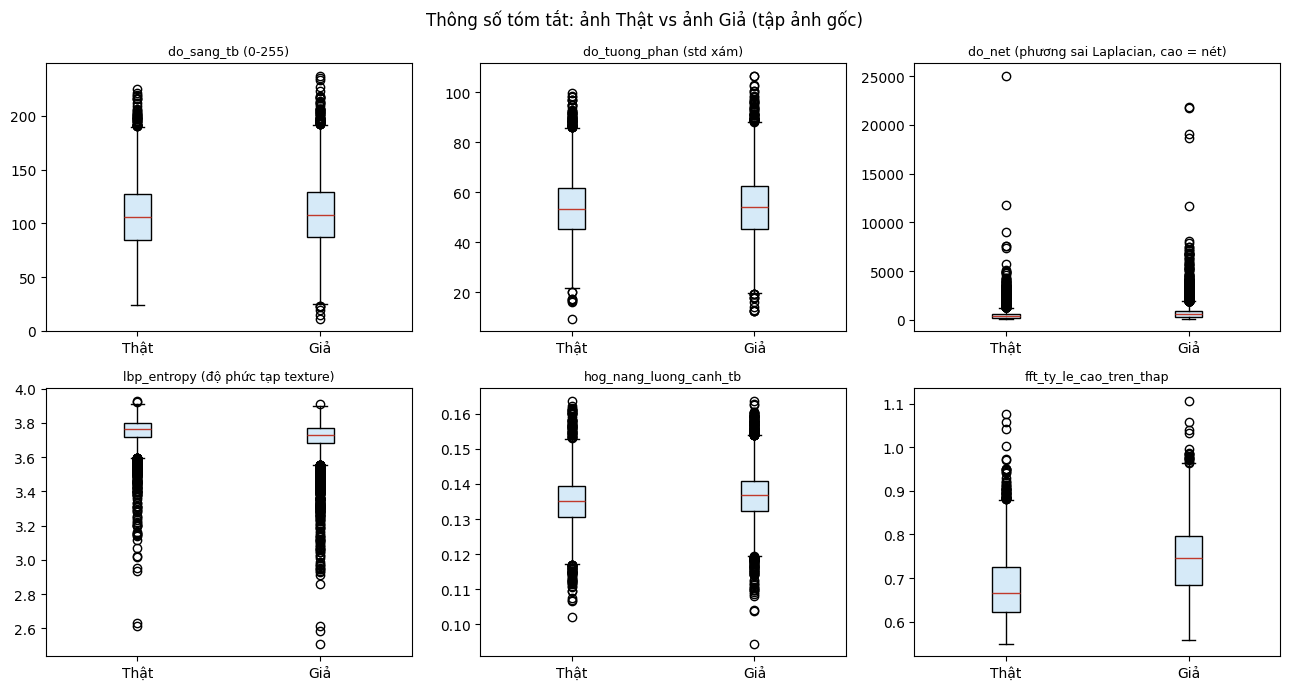

In [19]:
# ===================== 2.1d SO SÁNH ẢNH THẬT vs GIẢ (dùng ảnh gốc, không tính ảnh augment) =====================
cot_so = [c for c in tom_tat_df.columns if c not in ("ten_file", "tap", "nhan", "la_anh_augment")]
goc = tom_tat_df[~tom_tat_df["la_anh_augment"]]
tb = goc.groupby("nhan")[cot_so].mean().T
tb.columns = [f"trung_binh_{c}" for c in tb.columns]
tb["chenh_lech_%"] = (tb.iloc[:, 1] - tb.iloc[:, 0]) / (tb.iloc[:, 0].abs() + 1e-9) * 100
tb.round(3).to_csv(os.path.join(OUTPUT_DIR, "so_sanh_that_gia.csv"), encoding="utf-8-sig")
display(tb.round(3))

chon = cot_so[:2] + cot_so[2:3] + [c for c in cot_so if c.startswith(("lbp_entropy", "fft_ty_le", "hog_nang"))]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.ravel(), chon):
    data = [goc.loc[goc["nhan"] == n, c].values for n in ("Thật (Real)", "Giả (Fake)")]
    ax.boxplot(data, patch_artist=True, boxprops=dict(facecolor="#d6eaf8"), medianprops=dict(color="#c0392b"))
    ax.set_xticks([1, 2]); ax.set_xticklabels(["Thật", "Giả"])
    ax.set_title(c, fontsize=9)
plt.suptitle("Thông số tóm tắt: ảnh Thật vs ảnh Giả (tập ảnh gốc)", fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "so_sanh_that_gia.png"), dpi=150)
plt.show()

## 3. Phân tích khám phá dữ liệu — EDA (tương đương `src/eda.py`)

Trực quan hoá tập đặc trưng vừa trích xuất: phân bố lớp, khả năng phân
tách của dữ liệu (PCA/t-SNE), và tương quan giữa các đặc trưng. Các biểu
đồ vừa hiện trực tiếp trong notebook, vừa được lưu vào `outputs/eda/`.

In [20]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler


def plot_class_distribution(df: pd.DataFrame, out_dir: str):
    counts = df["label"].value_counts().sort_index()
    labels = ["Fake (0)", "Real (1)"]
    plt.figure(figsize=(5, 4))
    plt.bar(labels, [counts.get(0, 0), counts.get(1, 0)], color=["#e74c3c", "#2ecc71"])
    plt.title("Phân bố số lượng mẫu Real / Fake")
    plt.ylabel("Số lượng ảnh")
    for i, v in enumerate([counts.get(0, 0), counts.get(1, 0)]):
        plt.text(i, v, str(v), ha="center", va="bottom")
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, "class_distribution.png"), dpi=150)
    plt.show()


def plot_feature_projection(X: np.ndarray, y: np.ndarray, out_dir: str, method: str = "pca"):
    """Chiếu vector đặc trưng nhiều chiều xuống 2D để quan sát khả năng phân tách."""
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    if method == "pca":
        reducer = PCA(n_components=2, random_state=42)
        title = "Chiếu đặc trưng xuống 2D bằng PCA"
        fname = "pca_projection.png"
    else:
        reducer = TSNE(n_components=2, random_state=42, init="pca", perplexity=30)
        title = "Chiếu đặc trưng xuống 2D bằng t-SNE"
        fname = "tsne_projection.png"

    X_2d = reducer.fit_transform(X_scaled)

    plt.figure(figsize=(6, 5))
    for label_val, label_name, color in [(0, "Fake", "#e74c3c"), (1, "Real", "#2ecc71")]:
        mask = y == label_val
        plt.scatter(X_2d[mask, 0], X_2d[mask, 1], s=10, alpha=0.6, label=label_name, color=color)
    plt.legend()
    plt.title(title)
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, fname), dpi=150)
    plt.show()


def plot_feature_correlation_sample(df: pd.DataFrame, out_dir: str, n_features: int = 30):
    """Ma trận tương quan của N đặc trưng đầu tiên (không lấy hết vì quá nhiều cột)."""
    exclude = {"label", "split"}
    feat_cols = [c for c in df.columns if c not in exclude][:n_features]
    corr = df[feat_cols].corr()
    plt.figure(figsize=(8, 7))
    plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    plt.colorbar(label="Hệ số tương quan")
    plt.title(f"Tương quan giữa {n_features} đặc trưng đầu tiên")
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, "feature_correlation.png"), dpi=150)
    plt.show()


def run_eda(df: pd.DataFrame, out_dir: str):
    os.makedirs(out_dir, exist_ok=True)
    y = df["label"].values
    X = df.drop(columns=[c for c in ("label", "split") if c in df.columns]).values

    print(f"[INFO] Tổng số mẫu: {len(df)} | Số đặc trưng: {X.shape[1]}")

    plot_class_distribution(df, out_dir)
    plot_feature_projection(X, y, out_dir, method="pca")
    plot_feature_projection(X, y, out_dir, method="tsne")
    plot_feature_correlation_sample(df, out_dir)

    print(f"[OK] Đã lưu các biểu đồ EDA vào: {out_dir}")


### Chạy EDA

[INFO] Tổng số mẫu: 15581 | Số đặc trưng: 2311


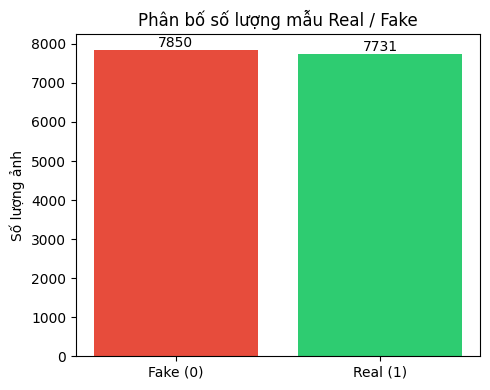

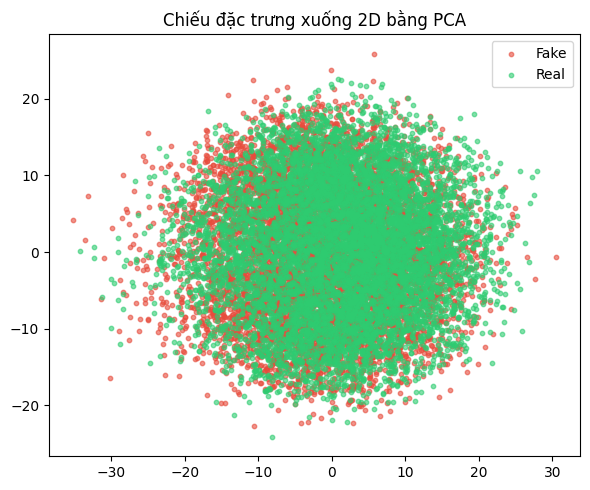

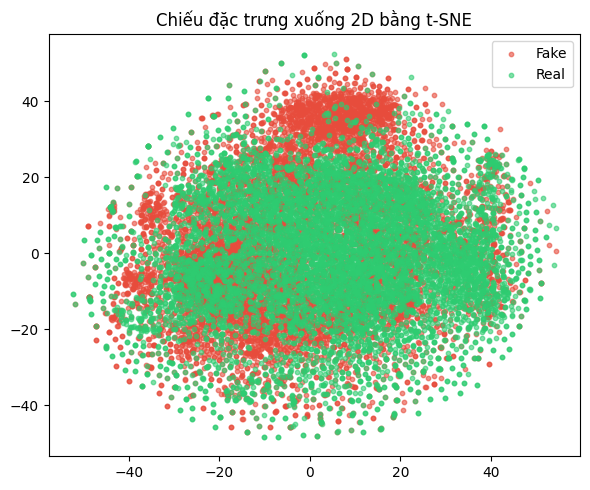

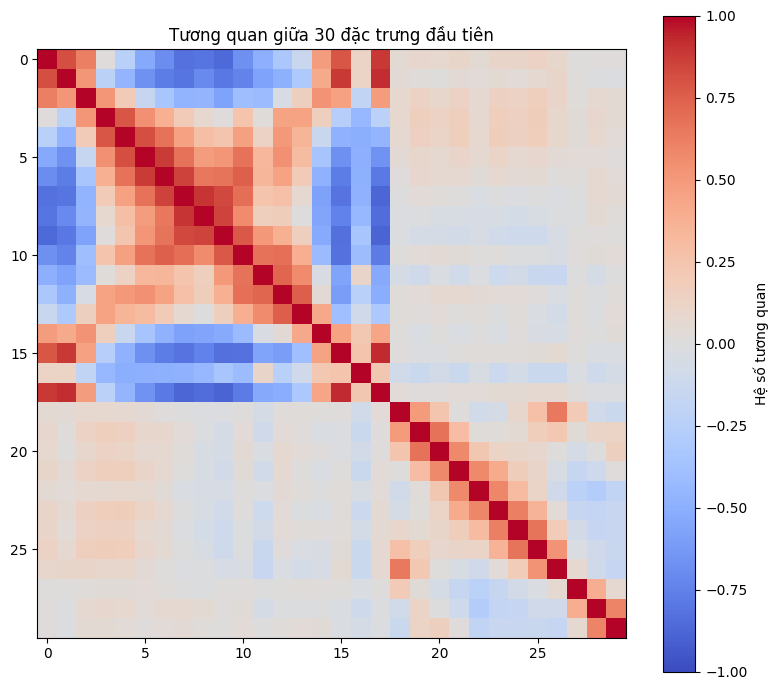

[OK] Đã lưu các biểu đồ EDA vào: outputs/eda


In [21]:
run_eda(features_df, EDA_DIR)


## 4. Huấn luyện & so sánh các thuật toán ML (tương đương `src/train_models.py`)

Huấn luyện 7 thuật toán ML truyền thống trên tập đặc trưng:

- Logistic Regression
- K-Nearest Neighbors (KNN)
- Naive Bayes
- Decision Tree
- Random Forest
- SVM (RBF kernel)
- Gradient Boosting

Sau khi train xong: in bảng so sánh Accuracy/Precision/Recall/F1/AUC, vẽ
confusion matrix từng model, vẽ biểu đồ so sánh, và lưu model tốt nhất
(theo F1-score) ra `outputs/best_model.pkl`.

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
)


def get_models() -> dict:
    # class_weight="balanced" giúp model không thiên vị lớp đa số, đóng vai
    # trò lớp bảo hiểm thứ 2 bên cạnh bước cân bằng lớp bằng augmentation ở
    # Bước 1 (phòng khi dữ liệu vẫn còn lệch nhẹ sau bước đó). KNN,
    # NaiveBayes, GradientBoosting (bản sklearn) không hỗ trợ tham số này.
    return {
        "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced"),
        "KNN": KNeighborsClassifier(n_neighbors=7),
        "NaiveBayes": GaussianNB(),
        "DecisionTree": DecisionTreeClassifier(max_depth=12, random_state=42, class_weight="balanced"),
        "RandomForest": RandomForestClassifier(
            n_estimators=300, random_state=42, n_jobs=-1, class_weight="balanced"
        ),
        "SVM_RBF": SVC(kernel="rbf", C=2.0, probability=True, random_state=42, class_weight="balanced"),
        "GradientBoosting": GradientBoostingClassifier(random_state=42),
    }


def evaluate_model(model, X_test, y_test) -> dict:
    y_pred = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = y_pred

    return {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "auc": roc_auc_score(y_test, y_score),
        "y_pred": y_pred,
    }


def plot_confusion_matrix(y_test, y_pred, model_name: str, out_dir: str):
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 4))
    plt.imshow(cm, cmap="Blues")
    plt.title(f"Confusion Matrix - {model_name}")
    plt.xticks([0, 1], ["Fake", "Real"])
    plt.yticks([0, 1], ["Fake", "Real"])
    plt.xlabel("Dự đoán")
    plt.ylabel("Thực tế")
    for i in range(2):
        for j in range(2):
            plt.text(j, i, str(cm[i, j]), ha="center", va="center",
                      color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, f"cm_{model_name}.png"), dpi=150)
    plt.show()


def plot_comparison_chart(results_df: pd.DataFrame, out_dir: str):
    metrics = ["accuracy", "precision", "recall", "f1", "auc"]
    x = np.arange(len(results_df))
    width = 0.15

    plt.figure(figsize=(11, 6))
    for i, m in enumerate(metrics):
        plt.bar(x + i * width, results_df[m], width, label=m)

    plt.xticks(x + width * 2, results_df["model"], rotation=20)
    plt.ylabel("Điểm số")
    plt.title("So sánh các thuật toán Machine Learning")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(out_dir, "model_comparison.png"), dpi=150)
    plt.show()


In [23]:
def run_training(features_csv: str, out_dir: str, test_size: float = 0.2):
    os.makedirs(out_dir, exist_ok=True)
    df = pd.read_csv(features_csv)

    if "split" in df.columns:
        # features.csv được sinh từ data/processed/train|test/... (Bước 1)
        # -> dùng đúng phần chia train/test đã làm ở bước tiền xử lý (train
        # được augment để cân bằng lớp, test giữ nguyên phân bố tự nhiên).
        # Không chia ngẫu nhiên lại ở đây để tránh phá vỡ việc chống data leakage.
        print("[INFO] Tìm thấy cột 'split' -> dùng train/test đã chia sẵn từ Bước 1 "
              "(chống data leakage do augmentation).")
        train_df = df[df["split"] == "train"]
        test_df = df[df["split"] == "test"]
        y_train = train_df["label"].values
        X_train = train_df.drop(columns=["label", "split"]).values
        y_test = test_df["label"].values
        X_test = test_df.drop(columns=["label", "split"]).values
    else:
        # Cấu trúc cũ (không qua Bước 1) -> tự chia ngẫu nhiên, giữ tương thích ngược.
        print("[INFO] Không có cột 'split' -> tự chia train/test ngẫu nhiên "
              f"(test_size={test_size}). Khuyến nghị chạy Bước 1 trước nếu dữ liệu "
              "có dùng augmentation để tránh data leakage.")
        y = df["label"].values
        X = df.drop(columns=["label"]).values
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, stratify=y, random_state=42
        )

    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)

    models = get_models()
    results = []
    trained_models = {}

    for name, model in models.items():
        print(f"[TRAIN] {name} ...")
        model.fit(X_train_s, y_train)
        metrics = evaluate_model(model, X_test_s, y_test)

        print(classification_report(y_test, metrics["y_pred"], target_names=["Fake", "Real"]))
        plot_confusion_matrix(y_test, metrics["y_pred"], name, out_dir)

        results.append({
            "model": name,
            "accuracy": metrics["accuracy"],
            "precision": metrics["precision"],
            "recall": metrics["recall"],
            "f1": metrics["f1"],
            "auc": metrics["auc"],
        })
        trained_models[name] = model

    results_df = pd.DataFrame(results).sort_values("f1", ascending=False).reset_index(drop=True)
    results_df.to_csv(os.path.join(out_dir, "model_comparison.csv"), index=False)
    plot_comparison_chart(results_df, out_dir)

    print("\n===== BẢNG SO SÁNH KẾT QUẢ (sắp xếp theo F1-score) =====")
    print(results_df.to_string(index=False))

    best_name = results_df.iloc[0]["model"]
    best_model = trained_models[best_name]
    print(f"\n[BEST MODEL] {best_name} (F1 = {results_df.iloc[0]['f1']:.4f})")

    joblib.dump(
        {"model": best_model, "scaler": scaler, "model_name": best_name},
        os.path.join(out_dir, "best_model.pkl"),
    )
    print(f"[OK] Đã lưu model tốt nhất -> {os.path.join(out_dir, 'best_model.pkl')}")

    return results_df


### Chạy huấn luyện & so sánh

[INFO] Tìm thấy cột 'split' -> dùng train/test đã chia sẵn từ Bước 1 (chống data leakage do augmentation).
[TRAIN] LogisticRegression ...
              precision    recall  f1-score   support

        Fake       0.77      0.76      0.77      1570
        Real       0.75      0.76      0.75      1451

    accuracy                           0.76      3021
   macro avg       0.76      0.76      0.76      3021
weighted avg       0.76      0.76      0.76      3021



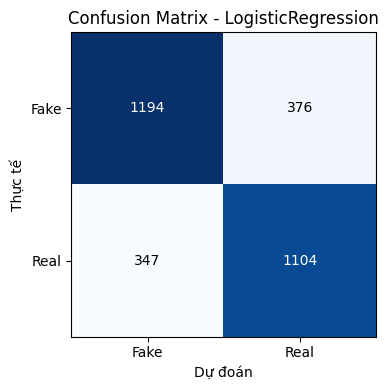

[TRAIN] KNN ...
              precision    recall  f1-score   support

        Fake       0.63      0.83      0.72      1570
        Real       0.72      0.48      0.58      1451

    accuracy                           0.66      3021
   macro avg       0.68      0.66      0.65      3021
weighted avg       0.68      0.66      0.65      3021



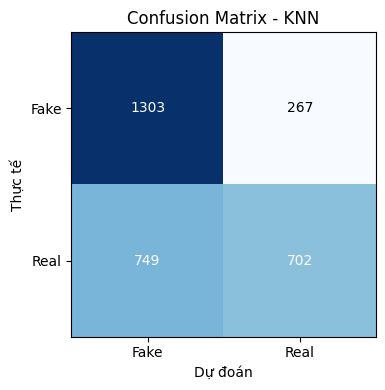

[TRAIN] NaiveBayes ...
              precision    recall  f1-score   support

        Fake       0.72      0.55      0.62      1570
        Real       0.61      0.77      0.68      1451

    accuracy                           0.65      3021
   macro avg       0.66      0.66      0.65      3021
weighted avg       0.66      0.65      0.65      3021



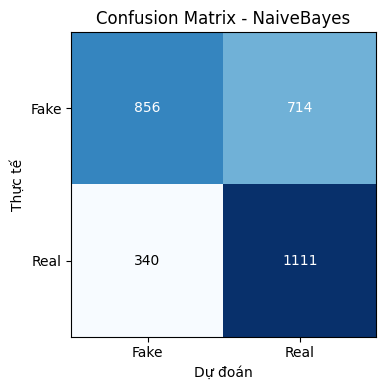

[TRAIN] DecisionTree ...
              precision    recall  f1-score   support

        Fake       0.70      0.66      0.68      1570
        Real       0.65      0.69      0.67      1451

    accuracy                           0.67      3021
   macro avg       0.68      0.68      0.67      3021
weighted avg       0.68      0.67      0.67      3021



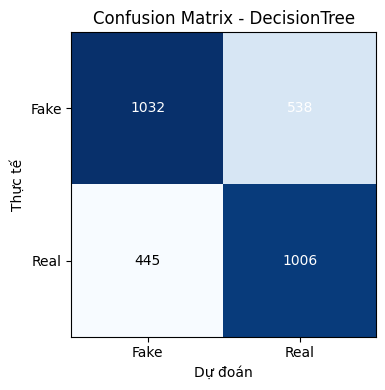

[TRAIN] RandomForest ...
              precision    recall  f1-score   support

        Fake       0.78      0.80      0.79      1570
        Real       0.77      0.76      0.77      1451

    accuracy                           0.78      3021
   macro avg       0.78      0.78      0.78      3021
weighted avg       0.78      0.78      0.78      3021



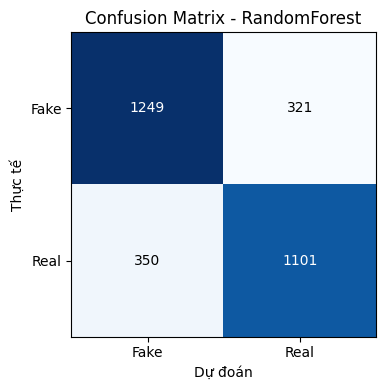

[TRAIN] SVM_RBF ...
              precision    recall  f1-score   support

        Fake       0.82      0.83      0.82      1570
        Real       0.81      0.81      0.81      1451

    accuracy                           0.82      3021
   macro avg       0.82      0.82      0.82      3021
weighted avg       0.82      0.82      0.82      3021



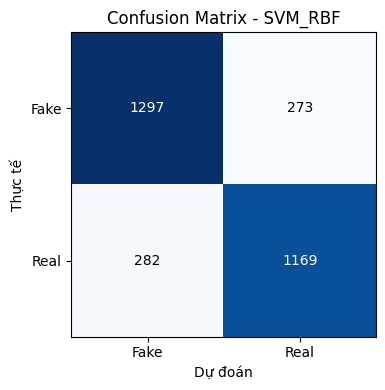

[TRAIN] GradientBoosting ...
              precision    recall  f1-score   support

        Fake       0.81      0.80      0.81      1570
        Real       0.79      0.80      0.79      1451

    accuracy                           0.80      3021
   macro avg       0.80      0.80      0.80      3021
weighted avg       0.80      0.80      0.80      3021



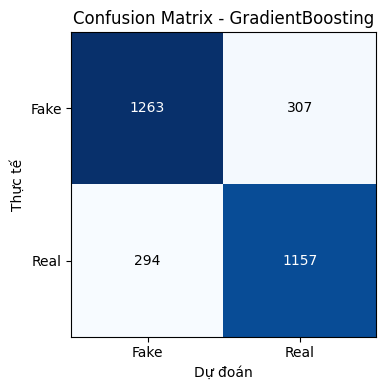

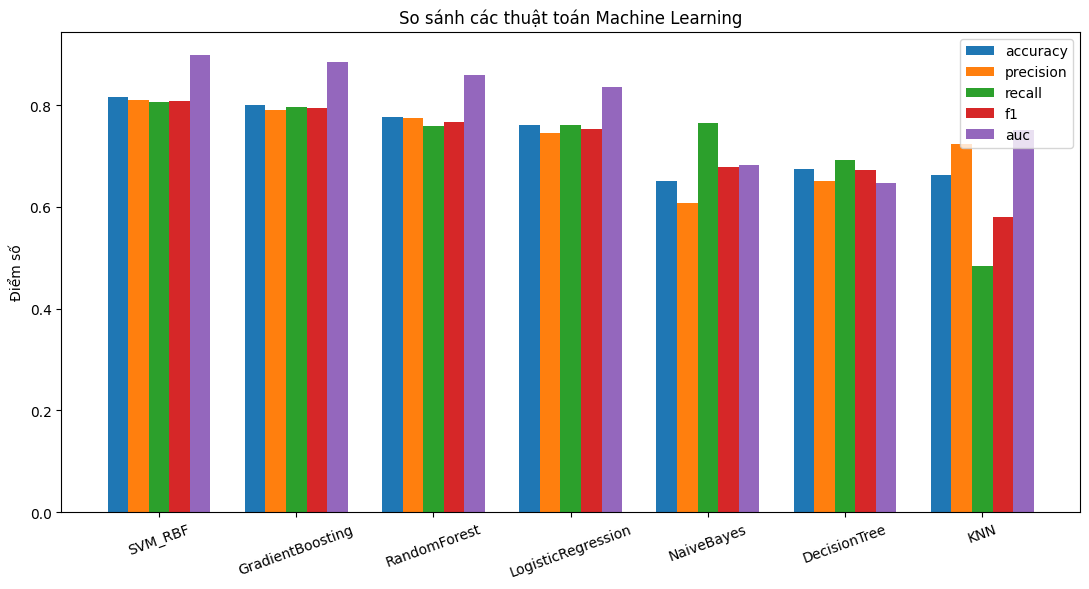


===== BẢNG SO SÁNH KẾT QUẢ (sắp xếp theo F1-score) =====
             model  accuracy  precision   recall       f1      auc
           SVM_RBF  0.816286   0.810680 0.805651 0.808158 0.899414
  GradientBoosting  0.801059   0.790301 0.797381 0.793825 0.885544
      RandomForest  0.777888   0.774262 0.758787 0.766446 0.860290
LogisticRegression  0.760675   0.745946 0.760855 0.753327 0.836664
        NaiveBayes  0.651109   0.608767 0.765679 0.678266 0.683179
      DecisionTree  0.674611   0.651554 0.693315 0.671786 0.648045
               KNN  0.663688   0.724458 0.483804 0.580165 0.751858

[BEST MODEL] SVM_RBF (F1 = 0.8082)
[OK] Đã lưu model tốt nhất -> outputs/best_model.pkl


,model,accuracy,precision,recall,f1,auc
0,SVM_RBF,0.816286,0.810680,0.805651,0.808158,0.899414
1,GradientBoosting,0.801059,0.790301,0.797381,0.793825,0.885544
2,RandomForest,0.777888,0.774262,0.758787,0.766446,0.860290
3,LogisticRegression,0.760675,0.745946,0.760855,0.753327,0.836664
4,NaiveBayes,0.651109,0.608767,0.765679,0.678266,0.683179
5,DecisionTree,0.674611,0.651554,0.693315,0.671786,0.648045
6,KNN,0.663688,0.724458,0.483804,0.580165,0.751858


In [24]:
results_df = run_training(FEATURES_CSV, OUTPUT_DIR, test_size=0.2)
results_df


## 5. Kết quả & ghi chú báo cáo (ML ảnh)

- Quy trình: tiền xử lý (cắt mặt, lọc mờ/trùng, **chia train/test trước rồi mới augment** để tránh data leakage) → trích đặc trưng thủ công → EDA → so sánh 7 thuật toán ML.
- Mục "Data Cleaning / Preprocessing" của CRISP-DM chính là Bước 1; mục "Modeling/Evaluation" là Bước 4.

**Các file tạo ra** (trong `outputs/`):

- `features.csv`, `features_vi.csv` — bảng đặc trưng (máy đọc / tên cột tiếng Việt)
- `mo_ta_dac_trung.csv`, `mo_ta_nhom_dac_trung.csv` — từ điển và giải thích đặc trưng
- `dac_trung_tom_tat.csv`, `so_sanh_that_gia.csv/.png` — thông số tóm tắt, so sánh ảnh Thật vs Giả
- `eda/` — biểu đồ phân tích dữ liệu
- `model_comparison.csv/.png` — so sánh 7 thuật toán
- `cm_<model>.png` — confusion matrix từng thuật toán
- `best_model.pkl` — model ML tốt nhất (dùng lại ở phần video)